# Changes in this version (summary)

**Fixes**
* `torch.nn` / `torch.nn.functional` are now imported (`nn`, `F` were used but never imported).
* Generation keeps the **end** of a long prompt (it used to keep the beginning) and stops at **exactly 128 words**; the end-of-text token and empty/whitespace words are banned, so no prediction is short.
* DataLoader `persistent_workers=False` (idle persistent workers can keep a Kaggle run from finishing).
* Very long "words" (>200 characters) are tokenized in pieces, so one odd prompt cannot stall tokenization.

**Better results**
* Decoding: repetition penalty + no-repeat n-gram blocking against repetition loops; four settings are compared on held-out validation text (ROUGE-L) and the best is used for the test set.
* 400M training tokens (was 220M), weighted towards Supreme Court and High Court text like the test prompts.
* Dropout 0 (was 0.1). Validation uses 100 batches spread over all sources (was the first 50 = Supreme Court only); the full validation loss is also reported.
* The model initialisation is seeded (`torch.manual_seed(SEED)`), so runs are reproducible.
* Logged training loss is the average over the whole optimizer step; the loss plot adds a 50-step moving average.

**Re-runs and time limits**
* Progress bars; resume checkpoint every 500 steps; training stops cleanly before Kaggle's 12-hour limit and resumes on the next run.
* Finished work is re-used: tokenizer, token cache, trained model, local evaluation and predictions (also from an earlier run attached with *Add Input*). `USE_EXISTING_CHECKPOINT = "always"` re-uses an older model and only regenerates predictions.
* Predictions are saved every 25 prompts and resume after an interruption; the submission zip is verified.


## 1. Hugging Face Login

This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

if not torch.cuda.is_available():
    print("WARNING: GPU is not available. Kaggle free-tier GPU is strongly recommended for the full Phase-1 run.")
else:
    torch.set_float32_matmul_precision("high")

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

This keeps the starter notebook's configuration flow. The values below are chosen to satisfy the Phase-1 constraints while remaining practical on Kaggle free-tier GPU resources.

In [3]:
import os
import random
import json
import time
import math
import zipfile

ARCH_NAME = "A_GPT_MHA_LearnedPos"
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

DATA_SOURCES = {
    "supreme_court": {"file": "Phase_1_Pretraining/Train/train_supreme_court.json", "train_tokens": 200_000_000},
    "acts":          {"file": "Phase_1_Pretraining/Train/train_acts.json",          "train_tokens": 40_000_000},
    "high_courts":   {"file": "Phase_1_Pretraining/Train/train_high_courts.json",   "train_tokens": 120_000_000},
    "tribunals":     {"file": "Phase_1_Pretraining/Train/train_tribunals.json",     "train_tokens": 40_000_000},
}
TRAIN_TOKENS = sum(x["train_tokens"] for x in DATA_SOURCES.values())
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 1
SEED = 42
MODEL_CONTEXT_LENGTH = 2048
DROPOUT = 0.0
BPE_VOCAB_SIZE = 8192
BPE_TRAIN_WORDS = 300_000

TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 640
TEMPERATURE = 0.1
TOP_P = 0.95

OUTPUT_DIR = os.path.join("/kaggle/working/cs781_phase1", ARCH_NAME)
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-model-final")
COMMON_DIR = os.path.join("/kaggle/working/cs781_phase1", "common")
TOKENIZER_DIR = os.path.join(COMMON_DIR, "bpe_tokenizer_" + ARCH_NAME)
TOKEN_CACHE_DIR = os.path.join(COMMON_DIR, "token_cache_" + ARCH_NAME)
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
BEST_CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "best_model.pt")
TRAIN_CACHE_PATH = os.path.join(TOKEN_CACHE_DIR, "train_tokens.bin")
VAL_CACHE_PATH = os.path.join(TOKEN_CACHE_DIR, "val_tokens.bin")
CACHE_META_PATH = os.path.join(TOKEN_CACHE_DIR, "metadata.json")

PER_DEVICE_TRAIN_BATCH_SIZE = 2
PER_DEVICE_EVAL_BATCH_SIZE = 2
GRADIENT_ACCUMULATION_STEPS = 8
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1
WARMUP_STEPS = 500
LOGGING_STEPS = 100
EVAL_STEPS = 1000
MAX_EVAL_BATCHES = 100
MAX_GRAD_NORM = 1.0
NUM_WORKERS = 2
GENERATION_BATCH_SIZE = 1

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(COMMON_DIR, exist_ok=True)
os.makedirs(TOKEN_CACHE_DIR, exist_ok=True)

print("Configuration loaded.")
print("Architecture:", ARCH_NAME)
print("Training budgets:", {name: f"{spec['train_tokens']:,}" for name, spec in DATA_SOURCES.items()})
print(f"Total train tokens: {TRAIN_TOKENS:,}")
print(f"Validation tokens: {VAL_TOKENS:,}")

N_EMBD = 768
N_LAYER = 8
N_HEAD = 8
N_FF = 3072

CONFIG = {
    "architecture": ARCH_NAME,
    "type": "decoder-only",
    "d_model": N_EMBD,
    "n_layer": N_LAYER,
    "n_head": N_HEAD,
    "d_ff": N_FF,
    "context_length": MODEL_CONTEXT_LENGTH,
}

NOTEBOOK_START = time.time()

CHECKPOINT_STEPS = 500
TRAIN_TIME_LIMIT_HOURS = 9.0
USE_EXISTING_CHECKPOINT = "auto"
LAST_CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "last_checkpoint.pt")
TRAINING_STATE_PATH = os.path.join(OUTPUT_DIR, "training_state.json")
FULL_VAL_RESULTS_PATH = os.path.join(OUTPUT_DIR, "full_validation.json")
LOCAL_EVAL_RESULTS_PATH = os.path.join(OUTPUT_DIR, "local_decoding_eval.json")
PREDICTION_PARTIAL_PATH = os.path.join(OUTPUT_DIR, "prediction_partial.json")
PREDICTION_META_PATH = os.path.join(OUTPUT_DIR, "prediction_meta.json")

DECODING_CONFIGS = {
    "old_t0.1":         {"temperature": 0.1, "top_p": 0.95, "repetition_penalty": 1.0, "no_repeat_ngram": 0},
    "greedy_rep1.1_ng8": {"temperature": 0.0, "top_p": 1.0,  "repetition_penalty": 1.1, "no_repeat_ngram": 8},
    "greedy_rep1.2_ng8": {"temperature": 0.0, "top_p": 1.0,  "repetition_penalty": 1.2, "no_repeat_ngram": 8},
    "t0.3_rep1.1_ng8":   {"temperature": 0.3, "top_p": 0.9,  "repetition_penalty": 1.1, "no_repeat_ngram": 8},
}
TEST_DECODING = "auto"
LOCAL_EVAL_PAIRS = 50

def restore_from_kaggle_inputs():
    """Copy the outputs of an earlier run of this notebook (attached with "Add Input") into /kaggle/working,
    so the tokenizer, token cache, checkpoints and predictions are re-used instead of recomputed."""
    import shutil
    root = "/kaggle/input"
    if not os.path.isdir(root):
        return
    sources = []
    for dirpath, dirnames, _ in os.walk(root):
        if os.path.basename(dirpath) == "cs781_phase1":
            sources.append(dirpath)
            dirnames[:] = []
        elif dirpath[len(root):].count(os.sep) >= 5:
            dirnames[:] = []
    targets = [os.path.join("common", "bpe_tokenizer_" + ARCH_NAME), os.path.join("common", "token_cache_" + ARCH_NAME), ARCH_NAME]
    copied = 0
    for src_root in sources:
        for rel in targets:
            src_dir = os.path.join(src_root, rel)
            if not os.path.isdir(src_dir):
                continue
            for dirpath, _, filenames in os.walk(src_dir):
                for name in filenames:
                    src = os.path.join(dirpath, name)
                    dst = os.path.join("/kaggle/working/cs781_phase1", os.path.relpath(src, src_root))
                    if not os.path.exists(dst):
                        os.makedirs(os.path.dirname(dst), exist_ok=True)
                        shutil.copy2(src, dst)
                        copied += 1
    if copied:
        print(f"Restored {copied} file(s) from an earlier run found in {sources}.")

restore_from_kaggle_inputs()
print(f"Improved settings: {TRAIN_TOKENS:,} train tokens | dropout {DROPOUT} | test decoding: {TEST_DECODING} | "
      f"re-use existing model: {USE_EXISTING_CHECKPOINT}")

Configuration loaded.
Architecture: A_GPT_MHA_LearnedPos
Training budgets: {'supreme_court': '200,000,000', 'acts': '40,000,000', 'high_courts': '120,000,000', 'tribunals': '40,000,000'}
Total train tokens: 400,000,000
Validation tokens: 5,000,000
Improved settings: 400,000,000 train tokens | dropout 0.0 | test decoding: auto | re-use existing model: auto


## 4. Load Tokenizer

The supplied byte-level BPE tokenizer is used here; it is trained from the provided legal corpus and never uses a pretrained tokenizer.

In [4]:
from collections import Counter
SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]

class BPETokenizer:
    """
    BPE tokenizer based directly on the supplied course-assignment tokenizer.

    The byte-level representation and merge-learning logic are retained. Two small fixes are
    included so the notebook is executable at scale: the byte-token initialization bug is
    removed, and decoding distinguishes raw byte tokens from merged numeric tokens.
    """
    def __init__(self, vocab_size):
        self.vocab_size = int(vocab_size)
        self.token_to_id = {tok: i for i, tok in enumerate(SPECIAL_TOKENS)}
        self.id_to_token = {i: tok for i, tok in enumerate(SPECIAL_TOKENS)}
        self.merges = []
        self.merge_ranks = {}
        self._merge_map = {}
        self._byte_tokens = {str(i) for i in range(256)}
        self._word_cache = {}
        self.encode_word_cache_limit = 100_000

    def train(self, text):
        words = Counter(text.split())
        corpus = []
        for word, freq in words.items():
            tokens = [str(b) for b in word.encode("utf-8")]
            tokens.append("</w>")
            corpus.append([tokens, freq])

        for b in range(256):
            token = str(b)
            if token not in self.token_to_id:
                idx = len(self.token_to_id)
                self.token_to_id[token] = idx
                self.id_to_token[idx] = token

        if "</w>" not in self.token_to_id:
            idx = len(self.token_to_id)
            self.token_to_id["</w>"] = idx
            self.id_to_token[idx] = "</w>"

        while len(self.token_to_id) < self.vocab_size:
            pair_counts = Counter()
            for tokens, freq in corpus:
                for i in range(len(tokens) - 1):
                    if tokens[i] == "</w>" or tokens[i + 1] == "</w>":
                        continue
                    pair_counts[(tokens[i], tokens[i + 1])] += freq
            if not pair_counts:
                break
            max_count = max(pair_counts.values())
            if max_count <= 1:
                break
            best_pair = min(pair for pair, count in pair_counts.items() if count == max_count)
            a, b = best_pair
            merged = a + b
            if merged in self.token_to_id:
                break
            self.merges.append(best_pair)
            idx = len(self.token_to_id)
            self.token_to_id[merged] = idx
            self.id_to_token[idx] = merged

            new_corpus = []
            for tokens, freq in corpus:
                new_tokens = []
                i = 0
                while i < len(tokens):
                    if (
                        i + 1 < len(tokens)
                        and tokens[i] != "</w>"
                        and tokens[i + 1] != "</w>"
                        and tokens[i] == a
                        and tokens[i + 1] == b
                    ):
                        new_tokens.append(merged)
                        i += 2
                    else:
                        new_tokens.append(tokens[i])
                        i += 1
                new_corpus.append([new_tokens, freq])
            corpus = new_corpus

        self._rebuild_merge_maps()
        self._word_cache.clear()
        return len(self.token_to_id)

    def _rebuild_merge_maps(self):
        self.merge_ranks = {pair: i for i, pair in enumerate(self.merges)}
        self._merge_map = {a + b: (a, b) for a, b in self.merges}
        self._word_cache.clear()

    def _encode_word(self, word):
        if word in self._word_cache:
            return self._word_cache[word]
        if len(word) > 200:
            eow_id = self.token_to_id["</w>"]
            ids = []
            for k in range(0, len(word), 200):
                ids.extend(self._encode_word(word[k:k + 200])[:-1])
            return tuple(ids) + (eow_id,)
        tokens = [str(b) for b in word.encode("utf-8")]
        tokens.append("</w>")

        while len(tokens) > 1:
            best_rank = None
            best_index = -1
            for i in range(len(tokens) - 1):
                rank = self.merge_ranks.get((tokens[i], tokens[i + 1]))
                if rank is not None and (best_rank is None or rank < best_rank):
                    best_rank = rank
                    best_index = i
            if best_index < 0:
                break
            merged = tokens[best_index] + tokens[best_index + 1]
            tokens[best_index:best_index + 2] = [merged]

        ids = tuple(self.token_to_id.get(token, self.token_to_id["<unk>"]) for token in tokens)
        if len(self._word_cache) < self.encode_word_cache_limit:
            self._word_cache[word] = ids
        return ids

    def encode(self, text):
        ids = []
        for word in text.split():
            ids.extend(self._encode_word(word))
        return ids

    def decode(self, ids):
        words = []
        current = bytearray()
        for idx in ids:
            if int(idx) not in self.id_to_token:
                continue
            token = self.id_to_token[int(idx)]
            if token in SPECIAL_TOKENS:
                continue
            if token == "</w>":
                if current:
                    words.append(current.decode("utf-8", errors="replace"))
                    current = bytearray()
                continue
            current.extend(self._get_bytes(token))
        if current:
            words.append(current.decode("utf-8", errors="replace"))
        return " ".join(words)

    def _get_bytes(self, token):
        if token in self._merge_map:
            a, b = self._merge_map[token]
            return self._get_bytes(a) + self._get_bytes(b)
        if token in self._byte_tokens:
            return bytes([int(token)])
        return b""

    def get_vocab_size(self):
        return len(self.token_to_id)

    def save_pretrained(self, directory):
        os.makedirs(directory, exist_ok=True)
        data = {
            "vocab_size_requested": self.vocab_size,
            "token_to_id": self.token_to_id,
            "merges": self.merges,
        }
        with open(os.path.join(directory, "tokenizer.json"), "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)

    @classmethod
    def from_pretrained(cls, directory):
        with open(os.path.join(directory, "tokenizer.json"), "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls(data["vocab_size_requested"])
        tok.token_to_id = {str(k): int(v) for k, v in data["token_to_id"].items()}
        tok.id_to_token = {int(v): str(k) for k, v in tok.token_to_id.items()}
        tok.merges = [tuple(pair) for pair in data["merges"]]
        tok._rebuild_merge_maps()
        return tok

if os.path.exists(os.path.join(TOKENIZER_DIR, "tokenizer.json")):
    tokenizer = BPETokenizer.from_pretrained(TOKENIZER_DIR)
    VOCAB_SIZE = tokenizer.get_vocab_size()
    print("Loaded existing BPE tokenizer from:", TOKENIZER_DIR)
    print("Vocabulary size:", VOCAB_SIZE)
else:
    tokenizer = None
    VOCAB_SIZE = None
    print("No cached BPE tokenizer found; it will be trained from the provided legal corpus in Section 6.")

No cached BPE tokenizer found; it will be trained from the provided legal corpus in Section 6.


## 5. Download Training Data From Hugging Face

In [5]:
from huggingface_hub import hf_hub_download

source_paths = {}
for name, spec in DATA_SOURCES.items():
    path = hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=spec["file"],
        repo_type="dataset",
        token=HF_TOKEN,
    )
    source_paths[name] = path
    print(f"{name}: {path}")
print("Downloaded", len(source_paths), "training sources.")

Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

supreme_court: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

acts: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_acts.json


... (2 outputs left out)

high_courts: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_high_courts.json


Phase_1_Pretraining/Train/train_tribunal(…): reconstructing file:   0%|          |  0.00B / 6.48GB            

Phase_1_Pretraining/Train/train_tribunal(…): downloading bytes:           |  0.00B            

tribunals: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_tribunals.json
Downloaded 4 training sources.


## 6. Create Train and Validation Tokens Set

In [6]:
import os
import json
import time
import math
import random
from pathlib import Path

import hashlib

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
TOKEN_DTYPE = np.uint16

def stream_json_array(path, chunk_size=4 * 1024 * 1024):
    """Read a large JSON array one record at a time; never json.load the full file."""
    decoder = json.JSONDecoder()
    buffer = ""
    started = False
    with open(path, "r", encoding="utf-8") as f:
        while True:
            chunk = f.read(chunk_size)
            if chunk:
                buffer += chunk
            elif not buffer:
                break
            pos = 0
            while True:
                while pos < len(buffer) and buffer[pos].isspace():
                    pos += 1
                if not started:
                    if pos >= len(buffer):
                        break
                    if buffer[pos] != "[":
                        raise ValueError("Training file must be a top-level JSON array.")
                    started = True
                    pos += 1
                while pos < len(buffer) and buffer[pos].isspace():
                    pos += 1
                if pos >= len(buffer):
                    break
                if buffer[pos] == "]":
                    return
                if buffer[pos] == ",":
                    pos += 1
                    continue
                try:
                    obj, end = decoder.raw_decode(buffer, pos)
                except json.JSONDecodeError:
                    break
                yield obj
                pos = end
            buffer = buffer[pos:]

def record_text(record):
    text = record.get("text", "") if isinstance(record, dict) else ""
    return text if isinstance(text, str) else str(text)

def collect_tokenizer_text(source_paths, source_budgets, max_words):
    """Use a proportional sample from all four sources for BPE training."""
    total = sum(source_budgets.values())
    parts = []
    for name, path in source_paths.items():
        target = max(1, int(max_words * source_budgets[name] / total))
        words = []
        for record in stream_json_array(path):
            text = record_text(record)
            if text:
                words.extend(text.split())
            if len(words) >= target:
                break
        parts.append(" ".join(words[:target]))
        print(f"Tokenizer sample - {name}: {len(words[:target]):,} words")
    return " ".join(parts)

def load_or_build_token_cache(source_paths, source_budgets, tokenizer, val_total, train_path, val_path, meta_path):
    """Tokenize each source once and write fixed-size uint16 caches directly to disk."""
    expected = {"budgets": source_budgets, "val_total": val_total, "vocab": tokenizer.get_vocab_size()}
    if os.path.exists(meta_path) and os.path.exists(train_path) and os.path.exists(val_path):
        try:
            with open(meta_path, "r", encoding="utf-8") as f:
                meta = json.load(f)
            if all(meta.get(k) == v for k, v in expected.items()):
                print("Using existing token cache.")
                return meta["train_tokens"], meta["val_tokens"]
        except Exception:
            pass

    train_target = sum(source_budgets.values()) + 1
    val_budgets = {k: max(1, int(val_total * v / sum(source_budgets.values()))) for k, v in source_budgets.items()}
    val_target = sum(val_budgets.values()) + 1
    train_mm = np.memmap(train_path, dtype=TOKEN_DTYPE, mode="w+", shape=(train_target,))
    val_mm = np.memmap(val_path, dtype=TOKEN_DTYPE, mode="w+", shape=(val_target,))
    train_pos = val_pos = 0

    for source_index, (name, path) in enumerate(source_paths.items()):
        train_limit = source_budgets[name]
        val_limit = val_budgets[name]
        source_train = source_val = 0
        rng = random.Random(SEED + source_index)
        for record in stream_json_array(path):
            text = record_text(record)
            if len(text) < 20:
                continue
            ids = tokenizer.encode(text)
            if not ids:
                continue
            if rng.random() < 0.05 and source_val < val_limit:
                take = min(len(ids), val_limit - source_val)
                val_mm[val_pos:val_pos + take] = ids[:take]
                val_pos += take
                source_val += take
            elif source_train < train_limit:
                take = min(len(ids), train_limit - source_train)
                train_mm[train_pos:train_pos + take] = ids[:take]
                train_pos += take
                source_train += take
            if source_train >= train_limit and source_val >= val_limit:
                break
        print(f"{name}: train {source_train:,} | val {source_val:,}")

    train_mm.flush(); val_mm.flush()
    del train_mm, val_mm
    if train_pos <= TRAIN_BLOCK_SIZE or val_pos <= TRAIN_BLOCK_SIZE:
        raise RuntimeError("Not enough tokenized data for one training block.")
    meta = {**expected, "train_tokens": train_pos, "val_tokens": val_pos}
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)
    print(f"Train tokens: {train_pos:,}")
    print(f"Validation tokens: {val_pos:,}")
    return train_pos, val_pos

def build_dataloader(dataset, batch_size, shuffle, num_workers):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers,
        pin_memory=torch.cuda.is_available(), drop_last=False,
        persistent_workers=False,
    )

class TokenBlockDataset(Dataset):
    def __init__(self, path, n_tokens, block_size):
        self.n_tokens = int(n_tokens)
        self.block_size = int(block_size)
        self.tokens = np.memmap(path, dtype=TOKEN_DTYPE, mode="r", shape=(self.n_tokens,))
        self.n_blocks = max(0, (self.n_tokens - 1) // self.block_size)
    def __len__(self):
        return self.n_blocks
    def __getitem__(self, idx):
        start = idx * self.block_size
        a = np.array(self.tokens[start:start + self.block_size + 1], dtype=np.int64)
        return {"input_ids": torch.from_numpy(a[:-1]), "labels": torch.from_numpy(a[1:])}

def build_optimizer(model, learning_rate, weight_decay):
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if param.ndim >= 2 and "norm" not in name.lower():
            decay.append(param)
        else:
            no_decay.append(param)
    return torch.optim.AdamW(
        [
            {"params": decay, "weight_decay": weight_decay},
            {"params": no_decay, "weight_decay": 0.0},
        ],
        lr=learning_rate,
        betas=(0.9, 0.95),
        eps=1e-8,
    )

def lr_for_step(step, total_steps, base_lr, warmup_steps, min_lr_ratio=0.1):
    if step <= warmup_steps:
        return base_lr * step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    cosine = 0.5 * (1.0 + math.cos(math.pi * min(1.0, max(0.0, progress))))
    return base_lr * (min_lr_ratio + (1.0 - min_lr_ratio) * cosine)

def set_lr(optimizer, lr):
    for group in optimizer.param_groups:
        group["lr"] = lr

@torch.no_grad()
def evaluate_loss(model, loader, model_kind, max_batches):
    model.eval()
    total_loss = 0.0
    batches = 0
    for batch in loader:
        if batches >= max_batches:
            break
        if model_kind == "encoder_decoder":
            src = batch["input_ids"].to(DEVICE, non_blocking=True)
            dec = batch["decoder_input_ids"].to(DEVICE, non_blocking=True)
            labels = batch["labels"].to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(src, dec)
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))
        else:
            x = batch["input_ids"].to(DEVICE, non_blocking=True)
            labels = batch["labels"].to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(x)
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))
        total_loss += float(loss.item())
        batches += 1
    if batches == 0:
        return float("inf")
    return total_loss / batches

def save_checkpoint(path, model, config_dict, step, eval_loss):
    state = {
        "model": model.state_dict(),
        "config": config_dict,
        "step": int(step),
        "eval_loss": float(eval_loss),
        "signature": training_signature(),
    }
    torch.save(state, path + ".tmp")
    os.replace(path + ".tmp", path)

def training_signature():
    """Everything that defines a training run. A saved model is only re-used ("auto") if this matches."""
    return {"budgets": {k: v["train_tokens"] for k, v in DATA_SOURCES.items()}, "val_tokens": VAL_TOKENS,
            "vocab_size": VOCAB_SIZE, "config": CONFIG, "dropout": DROPOUT, "lr": LEARNING_RATE, "wd": WEIGHT_DECAY,
            "warmup": WARMUP_STEPS, "batch": PER_DEVICE_TRAIN_BATCH_SIZE, "accum": GRADIENT_ACCUMULATION_STEPS,
            "block": TRAIN_BLOCK_SIZE, "epochs": EPOCHS, "seed": SEED}

def evenly_spaced_loader(dataset, n_batches, batch_size):
    """Validation subset spread over the whole validation set (all four sources), not just its beginning."""
    n_items = min(len(dataset), n_batches * batch_size)
    indices = sorted(set(int(round(x)) for x in np.linspace(0, len(dataset) - 1, n_items)))
    return DataLoader(torch.utils.data.Subset(dataset, indices), batch_size=batch_size, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

def train_loop(model, train_loader, val_loader, config_dict, model_kind):
    """Same training as before (AdamW, warmup + cosine, fp16 AMP, gradient accumulation), plus:
    progress bar, logged loss averaged over the whole optimizer step, validation spread over all sources,
    a resume checkpoint every CHECKPOINT_STEPS steps, and a clean stop before the Kaggle time limit."""
    model.to(DEVICE)
    optimizer = build_optimizer(model, LEARNING_RATE, WEIGHT_DECAY)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    dataset = train_loader.dataset
    n_micro = len(dataset) // PER_DEVICE_TRAIN_BATCH_SIZE + (1 if len(dataset) % PER_DEVICE_TRAIN_BATCH_SIZE else 0)
    total_steps = math.ceil(n_micro / GRADIENT_ACCUMULATION_STEPS) * EPOCHS
    signature = training_signature()

    global_step, best_eval, train_history, eval_history, seconds_before = 0, float("inf"), [], [], 0.0
    if os.path.exists(LAST_CHECKPOINT_PATH):
        ckpt = torch.load(LAST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
        if ckpt.get("signature") == signature:
            model.load_state_dict(ckpt["model"])
            optimizer.load_state_dict(ckpt["optimizer"])
            scaler.load_state_dict(ckpt["scaler"])
            global_step, best_eval = ckpt["step"], ckpt["best_eval"]
            train_history, eval_history = ckpt["train_history"], ckpt["eval_history"]
            seconds_before = ckpt["train_seconds"]
            print(f"Resuming training from step {global_step}/{total_steps} (best validation loss so far {best_eval:.4f}).")
        else:
            print("Ignoring last_checkpoint.pt: it belongs to a run with different settings.")
        del ckpt

    rng = np.random.default_rng(SEED)
    order = np.concatenate([rng.permutation(len(dataset)) for _ in range(EPOCHS)])
    steps_per_epoch = total_steps // EPOCHS
    start_item = 0
    for e in range(EPOCHS):
        done_in_epoch = min(max(global_step - e * steps_per_epoch, 0), steps_per_epoch)
        start_item += min(len(dataset), done_in_epoch * GRADIENT_ACCUMULATION_STEPS * PER_DEVICE_TRAIN_BATCH_SIZE)
    loader = DataLoader(dataset, batch_size=PER_DEVICE_TRAIN_BATCH_SIZE, sampler=order[start_item:].tolist(),
                        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), drop_last=False)
    eval_loader = evenly_spaced_loader(val_loader.dataset, MAX_EVAL_BATCHES, PER_DEVICE_EVAL_BATCH_SIZE)

    def save_last():
        tmp = LAST_CHECKPOINT_PATH + ".tmp"
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                    "step": global_step, "best_eval": best_eval, "train_history": train_history,
                    "eval_history": eval_history, "train_seconds": seconds_before + time.time() - start_time,
                    "signature": signature}, tmp)
        os.replace(tmp, LAST_CHECKPOINT_PATH)

    def save_best(val_loss):
        save_checkpoint(BEST_CHECKPOINT_PATH, model, config_dict, global_step, val_loss)

    start_time = time.time()
    model.train()
    optimizer.zero_grad(set_to_none=True)
    micro_in_step, loss_sum = 0, 0.0
    items_seen = start_item
    pbar = tqdm(total=total_steps, initial=global_step, desc="training", unit="step")
    for batch in loader:
        x = batch["input_ids"].to(DEVICE, non_blocking=True)
        labels = batch["labels"].to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(x)
            raw_loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))
        scaler.scale(raw_loss / GRADIENT_ACCUMULATION_STEPS).backward()
        loss_sum += float(raw_loss.item())
        micro_in_step += 1
        items_seen += x.size(0)
        end_of_epoch = items_seen % len(dataset) == 0
        if micro_in_step < GRADIENT_ACCUMULATION_STEPS and not end_of_epoch:
            continue

        global_step += 1
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        lr = lr_for_step(global_step, total_steps, LEARNING_RATE, WARMUP_STEPS)
        set_lr(optimizer, lr)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        step_loss = loss_sum / micro_in_step
        micro_in_step, loss_sum = 0, 0.0
        train_history.append((global_step, step_loss))
        pbar.update(1)

        if global_step % LOGGING_STEPS == 0 or global_step == 1:
            elapsed = seconds_before + time.time() - start_time
            pbar.set_postfix(loss=f"{step_loss:.3f}", lr=f"{lr:.2e}")
            print(f"step {global_step:6d}/{total_steps:<6d} | train loss {step_loss:.4f} | lr {lr:.3e} | "
                  f"elapsed {elapsed / 60:.1f} min", flush=True)

        if global_step % EVAL_STEPS == 0 or global_step == total_steps:
            val_loss = evaluate_loss(model, eval_loader, model_kind, MAX_EVAL_BATCHES)
            eval_history.append((global_step, val_loss))
            print(f"step {global_step:6d} | validation loss {val_loss:.4f} | perplexity {math.exp(min(val_loss, 20)):.3f}",
                  flush=True)
            if val_loss < best_eval:
                best_eval = val_loss
                save_best(val_loss)
            model.train()

        out_of_time = (time.time() - NOTEBOOK_START) / 3600 > TRAIN_TIME_LIMIT_HOURS
        if global_step % CHECKPOINT_STEPS == 0 or global_step == total_steps or out_of_time:
            save_last()
        if out_of_time and global_step < total_steps:
            pbar.close()
            raise RuntimeError(
                f"Stopped at step {global_step}/{total_steps} to stay inside Kaggle's time limit. A checkpoint is saved: "
                "attach this run's output with 'Add Input' and run the notebook again to resume training.")
    pbar.close()

    if not eval_history:
        val_loss = evaluate_loss(model, eval_loader, model_kind, MAX_EVAL_BATCHES)
        eval_history.append((global_step, val_loss))
        if val_loss < best_eval:
            best_eval = val_loss
            save_best(val_loss)
    if not os.path.exists(BEST_CHECKPOINT_PATH):
        save_best(best_eval)
    training_time = seconds_before + time.time() - start_time
    print(f"Final validation loss: {eval_history[-1][1]:.4f}")
    print(f"Training time: {training_time / 3600:.2f} hours")
    print(f"Training speed: {global_step * GRADIENT_ACCUMULATION_STEPS * PER_DEVICE_TRAIN_BATCH_SIZE * TRAIN_BLOCK_SIZE / max(1.0, training_time):,.0f} tokens/sec")
    with open(TRAINING_STATE_PATH, "w", encoding="utf-8") as f:
        json.dump({"signature": signature, "train_history": train_history, "eval_history": eval_history,
                   "best_eval": best_eval, "steps": global_step, "train_seconds": training_time}, f)
    return train_history, eval_history, best_eval, global_step

def sample_top_p(logits, temperature, top_p):
    temperature = max(float(temperature), 1e-5)
    top_p = float(top_p)
    logits = logits.float() / temperature
    sorted_logits, sorted_indices = torch.sort(logits, descending=True)
    sorted_probs = torch.softmax(sorted_logits, dim=-1)
    cumulative_probs = torch.cumsum(sorted_probs, dim=-1)
    remove = cumulative_probs > top_p
    remove[..., 1:] = remove[..., :-1].clone()
    remove[..., 0] = False
    sorted_probs = sorted_probs.masked_fill(remove, 0.0)
    sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
    sampled = torch.multinomial(sorted_probs, num_samples=1)
    return sorted_indices.gather(-1, sampled).squeeze(-1)

if tokenizer is None:
    tokenizer_text = collect_tokenizer_text(
        source_paths,
        {k: v["train_tokens"] for k, v in DATA_SOURCES.items()},
        BPE_TRAIN_WORDS,
    )
    tokenizer = BPETokenizer(BPE_VOCAB_SIZE)
    tokenizer.train(tokenizer_text)
    tokenizer.save_pretrained(TOKENIZER_DIR)
    print("BPE tokenizer trained and saved.")

VOCAB_SIZE = tokenizer.get_vocab_size()
print("Vocabulary size:", VOCAB_SIZE)
if VOCAB_SIZE > 65535:
    raise RuntimeError("BPE vocabulary must stay below 65536 for uint16 token storage.")

train_tokens_count, val_tokens_count = load_or_build_token_cache(
    source_paths,
    {k: v["train_tokens"] for k, v in DATA_SOURCES.items()},
    tokenizer,
    VAL_TOKENS + 1,
    TRAIN_CACHE_PATH,
    VAL_CACHE_PATH,
    CACHE_META_PATH,
)
print(f"Train tokens: {train_tokens_count:,}")
print(f"Validation tokens: {val_tokens_count:,}")

Tokenizer sample - supreme_court: 150,000 words
Tokenizer sample - acts: 30,000 words
Tokenizer sample - high_courts: 90,000 words
Tokenizer sample - tribunals: 30,000 words
BPE tokenizer trained and saved.
Vocabulary size: 8192
supreme_court: train 200,000,000 | val 2,500,000
acts: train 40,000,000 | val 500,000
high_courts: train 120,000,000 | val 1,500,000
tribunals: train 40,000,000 | val 500,000
Train tokens: 400,000,000
Validation tokens: 5,000,000
Train tokens: 400,000,000
Validation tokens: 5,000,000


## 7. Create Token Blocks

In [7]:
print("Training block size:", TRAIN_BLOCK_SIZE)
print("Model context length:", MODEL_CONTEXT_LENGTH)

Training block size: 2048
Model context length: 2048


## 8. Create Datasets

In [8]:
def causal_mask(q_len, k_len, past_len=0, device=None):
    q_pos = torch.arange(past_len, past_len + q_len, device=device)
    k_pos = torch.arange(0, k_len, device=device)
    return k_pos.unsqueeze(0) > q_pos.unsqueeze(1)

def local_causal_mask(q_len, k_len, past_len, window_size, device=None):
    q_pos = torch.arange(past_len, past_len + q_len, device=device)
    k_pos = torch.arange(0, k_len, device=device)
    future = k_pos.unsqueeze(0) > q_pos.unsqueeze(1)
    too_old = k_pos.unsqueeze(0) < (q_pos.unsqueeze(1) - window_size + 1)
    return future | too_old

train_dataset = TokenBlockDataset(TRAIN_CACHE_PATH, train_tokens_count, TRAIN_BLOCK_SIZE)
val_dataset = TokenBlockDataset(VAL_CACHE_PATH, val_tokens_count, TRAIN_BLOCK_SIZE)

train_loader = build_dataloader(train_dataset, PER_DEVICE_TRAIN_BATCH_SIZE, True, NUM_WORKERS)
val_loader = build_dataloader(val_dataset, PER_DEVICE_EVAL_BATCH_SIZE, False, NUM_WORKERS)

print("Training sequences:", len(train_dataset))
print("Validation sequences:", len(val_dataset))

Training sequences: 195312
Validation sequences: 2441


## 9. Define The Model

Architecture A — Decoder-only Transformer with MHA and learned positions

Substantially different baseline: standard multi-head causal self-attention, learned positional embeddings, LayerNorm, GELU.

All model parameters below are randomly initialized; no pretrained language model or pretrained model weights are loaded.

In [9]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def assert_parameter_range(model):
    params = count_parameters(model)
    print(f"Model size: {params / 1e6:.2f}M parameters")
    if not (50_000_000 <= params <= 300_000_000):
        raise RuntimeError(
            f"Phase-1 rule violation: model has {params:,} parameters; required range is 50M to 300M."
        )

def load_best_state(model):
    checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location="cpu")
    model.load_state_dict(checkpoint["model"], strict=True)
    print(f"Loaded best checkpoint from step {checkpoint['step']} with validation loss {checkpoint['eval_loss']:.4f}")
    return checkpoint

_GEN_CACHE = {}

def _generation_constants(tokenizer):
    """Token ids that must never be generated, and the end-of-word id."""
    key = id(tokenizer)
    if key not in _GEN_CACHE:
        banned = [tokenizer.token_to_id[t] for t in SPECIAL_TOKENS if t in tokenizer.token_to_id]
        banned += [tokenizer.token_to_id[str(b)] for b in list(range(0, 33)) + [127] if str(b) in tokenizer.token_to_id]
        _GEN_CACHE[key] = (torch.tensor(sorted(set(banned)), device=DEVICE), tokenizer.token_to_id["</w>"])
    return _GEN_CACHE[key]

@torch.no_grad()
def generate_continuation_decoder(prompt, model, tokenizer, target_words=128, decoding=None, seed=0):
    """Continue `prompt` with EXACTLY `target_words` words (the prompt is never included).

    Changes from the original version:
      * long prompts keep their END (the part the continuation depends on), not their beginning;
      * words are counted while generating (every word ends with the </w> token) and generation stops at exactly
        `target_words` words; the end-of-text token and empty/whitespace words are banned, so outputs are never short;
      * optional repetition penalty and no-repeat n-gram blocking on the generated text, against repetition loops;
      * temperature 0 = greedy decoding; sampling is seeded, so results are reproducible;
      * if the 2,048-token context fills up, the window slides instead of stopping.
    """
    cfg = decoding or DECODING_CONFIGS["greedy_rep1.1_ng8"]
    model.eval()
    banned, eow = _generation_constants(tokenizer)
    max_prompt = MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS
    context = tokenizer.encode(prompt) or [tokenizer.token_to_id["<s>"]]
    context = context[-max_prompt:]
    generator = torch.Generator(device=DEVICE.type).manual_seed(int(seed))
    seen = torch.zeros(model.token_embedding.num_embeddings, dtype=torch.bool, device=DEVICE)
    n = int(cfg["no_repeat_ngram"])
    ngrams = {}
    generated, words = [], 0
    max_new_tokens = 16 * target_words

    def prefill(ids):
        logits, past = model(torch.tensor([ids], device=DEVICE, dtype=torch.long), use_cache=True)
        return logits[0, -1].float(), past

    last, past = prefill(context)
    while words < target_words and len(generated) < max_new_tokens:
        if len(context) >= MODEL_CONTEXT_LENGTH:
            context = context[-max_prompt:]
            last, past = prefill(context)
        scores = last.clone()
        scores[banned] = float("-inf")
        if context[-1] == eow:
            scores[eow] = float("-inf")
        if cfg["repetition_penalty"] != 1.0 and generated:
            penalised = scores[seen]
            scores[seen] = torch.where(penalised > 0, penalised / cfg["repetition_penalty"],
                                       penalised * cfg["repetition_penalty"])
        if n > 1 and len(generated) >= n - 1:
            blocked = ngrams.get(tuple(generated[-(n - 1):]))
            if blocked:
                trial = scores.clone()
                trial[list(blocked)] = float("-inf")
                if torch.isfinite(trial).any():
                    scores = trial
        if cfg["temperature"] <= 0:
            next_id = int(torch.argmax(scores))
        else:
            probs = torch.softmax(scores / cfg["temperature"], dim=-1)
            if cfg["top_p"] < 1.0:
                sorted_probs, sorted_idx = torch.sort(probs, descending=True)
                keep = torch.cumsum(sorted_probs, dim=-1) - sorted_probs < cfg["top_p"]
                sorted_probs = sorted_probs * keep
                next_id = int(sorted_idx[torch.multinomial(sorted_probs / sorted_probs.sum(), 1, generator=generator)])
            else:
                next_id = int(torch.multinomial(probs, 1, generator=generator))
        if n > 1 and len(generated) >= n - 1:
            ngrams.setdefault(tuple(generated[-(n - 1):]), set()).add(next_id)
        generated.append(next_id)
        context.append(next_id)
        if next_id == eow:
            words += 1
        else:
            seen[next_id] = True
        if words >= target_words:
            words = len(tokenizer.decode(generated).split())
            if words >= target_words:
                break
        last, past = model(torch.tensor([[next_id]], device=DEVICE, dtype=torch.long), past_key_values=past, use_cache=True)
        last = last[0, -1].float()

    out = tokenizer.decode(generated).split()
    if len(out) < target_words:
        filler = out if out else ["the"]
        out = out + [filler[i % len(filler)] for i in range(target_words - len(out))]
    return " ".join(out[:target_words])

class CausalSelfAttentionMHA(nn.Module):
    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=True)
        self.out = nn.Linear(d_model, d_model, bias=True)
        self.dropout = dropout

    def forward(self, x, past_key_value=None, use_cache=False):
        b, t, c = x.shape
        qkv = self.qkv(x)
        q, k, v = qkv.chunk(3, dim=-1)
        q = q.view(b, t, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(b, t, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(b, t, self.n_heads, self.head_dim).transpose(1, 2)

        past_len = 0
        if past_key_value is not None:
            pk, pv = past_key_value
            past_len = pk.size(2)
            k = torch.cat([pk, k], dim=2)
            v = torch.cat([pv, v], dim=2)

        if past_len == 0:
            y = F.scaled_dot_product_attention(
                q, k, v,
                attn_mask=None,
                dropout_p=self.dropout if self.training else 0.0,
                is_causal=True,
            )
        else:
            mask = causal_mask(t, k.size(2), past_len, x.device)
            y = F.scaled_dot_product_attention(
                q, k, v,
                attn_mask=(~mask).view(1, 1, t, k.size(2)),
                dropout_p=self.dropout if self.training else 0.0,
                is_causal=False,
            )

        y = y.transpose(1, 2).contiguous().view(b, t, c)
        y = self.out(y)
        present = (k, v) if use_cache else None
        return y, present

class EncoderBlockA(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1 = nn.LayerNorm(N_EMBD)
        self.attn = CausalSelfAttentionMHA(N_EMBD, N_HEAD, DROPOUT)
        self.ln2 = nn.LayerNorm(N_EMBD)
        self.fc1 = nn.Linear(N_EMBD, N_FF)
        self.fc2 = nn.Linear(N_FF, N_EMBD)
        self.dropout = nn.Dropout(DROPOUT)

    def forward(self, x, past_key_value=None, use_cache=False):
        a, present = self.attn(self.ln1(x), past_key_value=past_key_value, use_cache=use_cache)
        x = x + self.dropout(a)
        m = self.fc2(F.gelu(self.fc1(self.ln2(x))))
        x = x + self.dropout(m)
        return x, present

class DecoderOnlyA(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(VOCAB_SIZE, N_EMBD)
        self.position_embedding = nn.Embedding(MODEL_CONTEXT_LENGTH, N_EMBD)
        self.blocks = nn.ModuleList([EncoderBlockA() for _ in range(N_LAYER)])
        self.ln_f = nn.LayerNorm(N_EMBD)
        self.config = CONFIG
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, past_key_values=None, use_cache=False):
        b, t = input_ids.shape
        past_len = 0 if past_key_values is None else past_key_values[0][0].size(2)
        if past_len + t > MODEL_CONTEXT_LENGTH:
            raise ValueError("Sequence exceeds MODEL_CONTEXT_LENGTH.")
        positions = torch.arange(past_len, past_len + t, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)[None, :, :]
        presents = []
        for i, block in enumerate(self.blocks):
            past = None if past_key_values is None else past_key_values[i]
            x, present = block(x, past_key_value=past, use_cache=use_cache)
            if use_cache:
                presents.append(present)
        x = self.ln_f(x)
        logits = F.linear(x, self.token_embedding.weight)
        if use_cache:
            return logits, tuple(presents)
        return logits

torch.manual_seed(SEED)
model = DecoderOnlyA().to(DEVICE)
assert_parameter_range(model)
print("Model configuration:")
print(json.dumps(CONFIG, indent=2))

Model size: 64.57M parameters
Model configuration:
{
  "architecture": "A_GPT_MHA_LearnedPos",
  "type": "decoder-only",
  "d_model": 768,
  "n_layer": 8,
  "n_head": 8,
  "d_ff": 3072,
  "context_length": 2048
}


## 10. Training Arguments

In [10]:
print("The model is trained from scratch with a custom PyTorch loop.")
print(f"Micro-batch size: {PER_DEVICE_TRAIN_BATCH_SIZE}")
print(f"Gradient accumulation: {GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective batch size: {PER_DEVICE_TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Warmup steps: {WARMUP_STEPS}")
print(f"FP16 AMP: {USE_AMP}")

The model is trained from scratch with a custom PyTorch loop.
Micro-batch size: 2
Gradient accumulation: 8
Effective batch size: 16
Learning rate: 0.0003
Weight decay: 0.1
Warmup steps: 500
FP16 AMP: True


## 11. Training

If a finished model with the same settings exists (or `USE_EXISTING_CHECKPOINT = "always"`), it is loaded and training is skipped. Otherwise training runs with a progress bar, saves `last_checkpoint.pt` every 500 steps, and resumes from it automatically after an interruption.

In [11]:
reuse_checkpoint = None
if USE_EXISTING_CHECKPOINT != "never" and os.path.exists(BEST_CHECKPOINT_PATH):
    saved = torch.load(BEST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    finished_same_run = False
    if os.path.exists(TRAINING_STATE_PATH):
        with open(TRAINING_STATE_PATH, "r", encoding="utf-8") as f:
            finished_same_run = json.load(f).get("signature") == training_signature()
    if USE_EXISTING_CHECKPOINT == "always" or (finished_same_run and saved.get("signature") == training_signature()):
        reuse_checkpoint = saved
    elif USE_EXISTING_CHECKPOINT == "auto":
        print("Found best_model.pt from a run with different settings (or an unfinished run); training with the current settings.")

if reuse_checkpoint is not None:
    model.load_state_dict(reuse_checkpoint["model"], strict=True)
    best_eval_loss, best_step = float(reuse_checkpoint["eval_loss"]), int(reuse_checkpoint["step"])
    history_file = TRAINING_STATE_PATH if os.path.exists(TRAINING_STATE_PATH) else os.path.join(MODEL_OUTPUT_DIR, "training_history.json")
    if os.path.exists(history_file):
        with open(history_file, "r", encoding="utf-8") as f:
            saved_history = json.load(f)
        train_history = [tuple(x) for x in saved_history["train_history"]]
        eval_history = [tuple(x) for x in saved_history["eval_history"]]
    else:
        train_history, eval_history = [], [(best_step, best_eval_loss)]
    print(f"Training skipped: re-using the saved model (step {best_step}, validation loss {best_eval_loss:.4f}).")
else:
    model.train()
    train_history, eval_history, best_eval_loss, best_step = train_loop(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        config_dict=CONFIG,
        model_kind="decoder_only"
    )
print("Best validation loss:", best_eval_loss)
print("Best checkpoint step:", best_step)

/tmp/ipykernel_24/3552499139.py:256: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


training:   0%|          | 0/12207 [00:00<?, ?step/s]

/tmp/ipykernel_24/3552499139.py:309: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


step      1/12207  | train loss 8.4691 | lr 6.000e-07 | elapsed 0.0 min
step    100/12207  | train loss 4.0511 | lr 6.000e-05 | elapsed 2.0 min
step    200/12207  | train loss 3.7715 | lr 1.200e-04 | elapsed 4.2 min
step    300/12207  | train loss 3.7332 | lr 1.800e-04 | elapsed 6.3 min
step    400/12207  | train loss 3.5174 | lr 2.400e-04 | elapsed 8.4 min
step    500/12207  | train loss 3.2809 | lr 3.000e-04 | elapsed 10.6 min
step    600/12207  | train loss 3.3921 | lr 3.000e-04 | elapsed 12.7 min
step    700/12207  | train loss 3.2136 | lr 2.998e-04 | elapsed 14.9 min
step    800/12207  | train loss 2.3701 | lr 2.996e-04 | elapsed 17.0 min
step    900/12207  | train loss 2.7561 | lr 2.992e-04 | elapsed 19.1 min
step   1000/12207  | train loss 2.4393 | lr 2.988e-04 | elapsed 21.3 min


/tmp/ipykernel_24/3552499139.py:212: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


step   1000 | validation loss 2.5605 | perplexity 12.942
step   1100/12207  | train loss 2.2497 | lr 2.983e-04 | elapsed 23.5 min
step   1200/12207  | train loss 2.0816 | lr 2.976e-04 | elapsed 25.6 min
step   1300/12207  | train loss 2.0873 | lr 2.969e-04 | elapsed 27.8 min
step   1400/12207  | train loss 2.2001 | lr 2.961e-04 | elapsed 29.9 min
step   1500/12207  | train loss 2.2843 | lr 2.952e-04 | elapsed 32.0 min
step   1600/12207  | train loss 1.9748 | lr 2.942e-04 | elapsed 34.2 min
step   1700/12207  | train loss 2.1032 | lr 2.931e-04 | elapsed 36.3 min
step   1800/12207  | train loss 2.1499 | lr 2.919e-04 | elapsed 38.4 min
step   1900/12207  | train loss 1.9539 | lr 2.906e-04 | elapsed 40.6 min
step   2000/12207  | train loss 1.9787 | lr 2.892e-04 | elapsed 42.7 min
step   2000 | validation loss 2.0414 | perplexity 7.701
step   2100/12207  | train loss 1.9007 | lr 2.877e-04 | elapsed 44.9 min
step   2200/12207  | train loss 1.8631 | lr 2.862e-04 | elapsed 47.1 min
step   2300

## 12. Perplexity

In [12]:
perplexity = math.exp(min(best_eval_loss, 20.0))
print(f"Validation loss (periodic subset): {best_eval_loss:.6f}")
print(f"Validation perplexity (periodic subset): {perplexity:.4f}")

best_state = torch.load(BEST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
full_val_key = {"step": int(best_state["step"]), "eval_loss": float(best_state["eval_loss"])}
full_val = None
if os.path.exists(FULL_VAL_RESULTS_PATH):
    with open(FULL_VAL_RESULTS_PATH, "r", encoding="utf-8") as f:
        full_val = json.load(f)
    if full_val.get("key") != full_val_key:
        full_val = None
if full_val is None:
    model.load_state_dict(best_state["model"], strict=True)
    model.to(DEVICE)
    loss = evaluate_loss(model, tqdm(val_loader, desc="full validation"), "decoder_only", 10 ** 9)
    full_val = {"key": full_val_key, "loss": loss}
    with open(FULL_VAL_RESULTS_PATH, "w", encoding="utf-8") as f:
        json.dump(full_val, f)
del best_state
print(f"Validation loss (full validation set): {full_val['loss']:.6f}")
print(f"Validation perplexity (full validation set): {math.exp(min(full_val['loss'], 20.0)):.4f}")

Validation loss (periodic subset): 1.308612
Validation perplexity (periodic subset): 3.7010


full validation:   0%|          | 0/1221 [00:00<?, ?it/s]

/tmp/ipykernel_24/3552499139.py:212: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Validation loss (full validation set): 1.314901
Validation perplexity (full validation set): 3.7244


## 13. Plot Training and Validation Loss

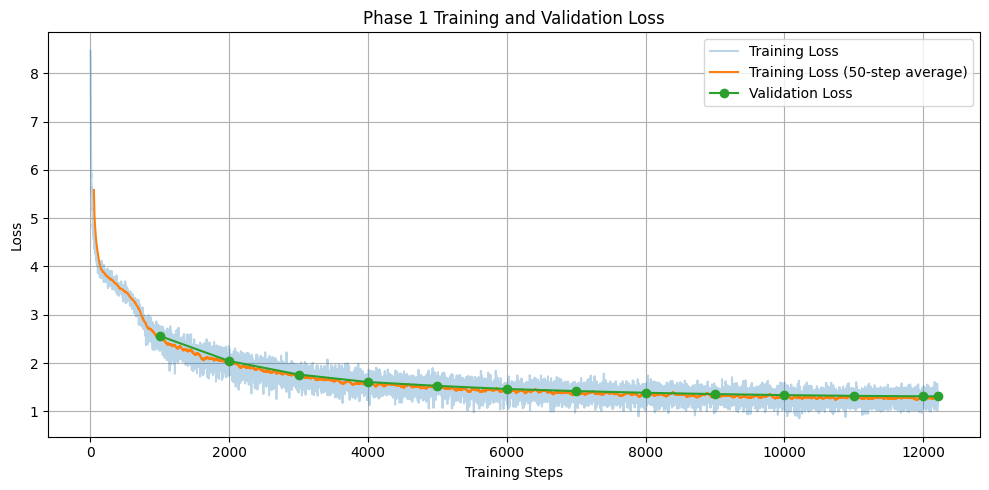

Loss plot saved to:
/kaggle/working/cs781_phase1/A_GPT_MHA_LearnedPos/training_validation_loss.png


In [13]:
import matplotlib.pyplot as plt

train_steps = [s for s, _ in train_history]
train_loss_values = [v for _, v in train_history]
eval_steps = [s for s, _ in eval_history]
eval_loss_values = [v for _, v in eval_history]

window = 50
smooth = np.convolve(train_loss_values, np.ones(window) / window, mode="valid") if len(train_loss_values) >= window else []

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss_values, label="Training Loss", alpha=0.3)
if len(smooth):
    plt.plot(train_steps[window - 1:], smooth, label=f"Training Loss ({window}-step average)")
plt.plot(eval_steps, eval_loss_values, label="Validation Loss", marker="o")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [14]:
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
best_checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location="cpu")
model.load_state_dict(best_checkpoint["model"], strict=True)

torch.save(
    {
        "model": model.state_dict(),
        "config": CONFIG,
        "tokenizer_vocab_size": tokenizer.get_vocab_size(),
        "best_eval_loss": float(best_checkpoint["eval_loss"]),
        "best_step": int(best_checkpoint["step"]),
    },
    os.path.join(MODEL_OUTPUT_DIR, "model.pt"),
)
with open(os.path.join(MODEL_OUTPUT_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

with open(os.path.join(MODEL_OUTPUT_DIR, "training_history.json"), "w", encoding="utf-8") as f:
    json.dump(
        {
            "train_history": train_history,
            "eval_history": eval_history,
            "best_eval_loss": float(best_eval_loss),
            "best_step": int(best_step),
        },
        f,
        indent=2,
    )

print("Final model saved to:")
print(MODEL_OUTPUT_DIR)

Final model saved to:
/kaggle/working/cs781_phase1/A_GPT_MHA_LearnedPos/legal-model-final


## 15. Push Model to Hugging Face Hub

In [15]:
print("Model push is intentionally disabled in the submission notebook.")

Model push is intentionally disabled in the submission notebook.


## 16. Load Test Data from HuggingFace

In [16]:
from huggingface_hub import hf_hub_download

test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN,
)

print("Test file:", test_file_path)

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [17]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))
if not isinstance(test_data, dict):
    raise TypeError("The starter submission pipeline expects test.json to be a JSON object keyed by official test IDs.")

Number of test examples: 1000


## 18. Load Final Model for Generation

In [18]:
generation_model = DecoderOnlyA().to(DEVICE)
load_best_state(generation_model)
generation_model.eval()
print("Device:", DEVICE)
print(f"Parameters: {count_parameters(generation_model) / 1e6:.2f}M")

generation_tokenizer = BPETokenizer.from_pretrained(MODEL_OUTPUT_DIR)
print("Generation tokenizer loaded.")

Loaded best checkpoint from step 12207 with validation loss 1.3086
Device: cuda
Parameters: 64.57M
Generation tokenizer loaded.


## 19. Generate 128 Words

Generate exactly the generated continuation. The prompt is never written to the prediction field. Generation stops at exactly 128 words. **19b** compares the decoding settings in `DECODING_CONFIGS` on held-out validation text and picks the best one for the test set (`TEST_DECODING = "auto"`).

In [19]:
def generate_batch(prompts, model, tokenizer, device, target_words=128, decoding=None, seeds=None):
    predictions = []
    for i, prompt in enumerate(prompts):
        seed = seeds[i] if seeds is not None else SEED + i
        predictions.append(generate_continuation_decoder(prompt, model, tokenizer, target_words=target_words,
                                                         decoding=decoding, seed=seed))
    return predictions

def rouge_l_f1(candidate, reference):
    c, r = candidate.split(), reference.split()
    if not c or not r:
        return 0.0
    prev = [0] * (len(r) + 1)
    for cw in c:
        cur = [0] * (len(r) + 1)
        for j, rw in enumerate(r, 1):
            cur[j] = prev[j - 1] + 1 if cw == rw else max(prev[j], cur[j - 1])
        prev = cur
    lcs = prev[-1]
    if lcs == 0:
        return 0.0
    p, rec = lcs / len(c), lcs / len(r)
    return 2 * p * rec / (p + rec)

def build_local_eval_pairs(n_pairs, window_tokens=2400):
    val_mm = np.memmap(VAL_CACHE_PATH, dtype=TOKEN_DTYPE, mode="r", shape=(val_tokens_count,))
    pairs = []
    for pos in np.linspace(0, max(0, val_tokens_count - window_tokens - 1), n_pairs * 2).astype(int):
        words = generation_tokenizer.decode(val_mm[pos:pos + window_tokens].tolist()).split()[1:]
        if len(words) >= 512 + TARGET_GENERATION_WORDS:
            pairs.append({"prompt": " ".join(words[:512]),
                          "reference": " ".join(words[512:512 + TARGET_GENERATION_WORDS])})
        if len(pairs) == n_pairs:
            break
    return pairs

generation_checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
checkpoint_key = {"step": int(generation_checkpoint["step"]), "eval_loss": float(generation_checkpoint["eval_loss"])}
del generation_checkpoint

local_eval = {"key": checkpoint_key, "pairs": LOCAL_EVAL_PAIRS, "results": {}}
if os.path.exists(LOCAL_EVAL_RESULTS_PATH):
    with open(LOCAL_EVAL_RESULTS_PATH, "r", encoding="utf-8") as f:
        saved_eval = json.load(f)
    if saved_eval.get("key") == checkpoint_key and saved_eval.get("pairs") == LOCAL_EVAL_PAIRS:
        local_eval = saved_eval

if TEST_DECODING == "auto" and LOCAL_EVAL_PAIRS > 0:
    eval_pairs = build_local_eval_pairs(LOCAL_EVAL_PAIRS)
    print(f"Local evaluation pairs: {len(eval_pairs)}")
    for name, cfg in DECODING_CONFIGS.items():
        if name in local_eval["results"] and local_eval["results"][name].get("config") == cfg:
            continue
        t0 = time.time()
        outputs = generate_batch([p["prompt"] for p in tqdm(eval_pairs, desc=f"local eval {name}")], generation_model,
                                 generation_tokenizer, DEVICE, TARGET_GENERATION_WORDS, decoding=cfg,
                                 seeds=[SEED + i for i in range(len(eval_pairs))])
        scores = [rouge_l_f1(o, p["reference"]) for o, p in zip(outputs, eval_pairs)]
        local_eval["results"][name] = {"config": cfg, "rougeL_f1": float(np.mean(scores)),
                                       "all_128_words": all(len(o.split()) == TARGET_GENERATION_WORDS for o in outputs),
                                       "seconds_per_prompt": (time.time() - t0) / max(1, len(outputs)),
                                       "example": outputs[0] if outputs else ""}
        with open(LOCAL_EVAL_RESULTS_PATH, "w", encoding="utf-8") as f:
            json.dump(local_eval, f, indent=2)
        print(f"{name:20s} ROUGE-L {local_eval['results'][name]['rougeL_f1']:.4f} | "
              f"{local_eval['results'][name]['seconds_per_prompt']:.2f} s/prompt", flush=True)

valid_results = {k: v for k, v in local_eval["results"].items() if k in DECODING_CONFIGS}
if TEST_DECODING != "auto":
    SELECTED_DECODING = TEST_DECODING
elif valid_results:
    SELECTED_DECODING = max(valid_results, key=lambda k: valid_results[k]["rougeL_f1"])
else:
    SELECTED_DECODING = "greedy_rep1.1_ng8"
for name, res in sorted(valid_results.items(), key=lambda kv: -kv[1]["rougeL_f1"]):
    print(f"  {name:20s} ROUGE-L {res['rougeL_f1']:.4f} | exactly 128 words: {res['all_128_words']}")
print("Decoding used for the test set:", SELECTED_DECODING, DECODING_CONFIGS[SELECTED_DECODING])
if SELECTED_DECODING in valid_results:
    print("Example:", valid_results[SELECTED_DECODING]["example"][:400], "...")

Local evaluation pairs: 50


local eval old_t0.1:   0%|          | 0/50 [00:00<?, ?it/s]

old_t0.1             ROUGE-L 0.1766 | 1.65 s/prompt


local eval greedy_rep1.1_ng8:   0%|          | 0/50 [00:00<?, ?it/s]

greedy_rep1.1_ng8    ROUGE-L 0.1939 | 1.59 s/prompt


local eval greedy_rep1.2_ng8:   0%|          | 0/50 [00:00<?, ?it/s]

greedy_rep1.2_ng8    ROUGE-L 0.1906 | 1.57 s/prompt


local eval t0.3_rep1.1_ng8:   0%|          | 0/50 [00:00<?, ?it/s]

t0.3_rep1.1_ng8      ROUGE-L 0.1950 | 1.71 s/prompt
  t0.3_rep1.1_ng8      ROUGE-L 0.1950 | exactly 128 words: True
  greedy_rep1.1_ng8    ROUGE-L 0.1939 | exactly 128 words: True
  greedy_rep1.2_ng8    ROUGE-L 0.1906 | exactly 128 words: True
  old_t0.1             ROUGE-L 0.1766 | exactly 128 words: True
Decoding used for the test set: t0.3_rep1.1_ng8 {'temperature': 0.3, 'top_p': 0.9, 'repetition_penalty': 1.1, 'no_repeat_ngram': 8}
Example: to land tenures in the State of Bombay and the provisions of the Act were not made applicable to the lands in the State but were not made applicable. The petitioners have also challenged the validity of the impugned Act. The petitioners have challenged the validity and the validity of s. 3 of the Act on the ground that the impugned Act was not within the competence of the State Legislature to enac ...


## 20. Generate Predictions for the Test Set

Predictions are saved every 25 prompts; if the run is interrupted, re-running resumes from there. If a complete `prediction.json` for the same model and decoding setting exists, generation is skipped.

In [20]:
items = list(test_data.items())
total_examples = len(items)
print(f"Total test examples: {total_examples}")

prediction_key = {"checkpoint": checkpoint_key, "decoding": SELECTED_DECODING,
                  "config": DECODING_CONFIGS[SELECTED_DECODING], "max_generation_tokens": MAX_GENERATION_TOKENS}

def predictions_complete(preds):
    return (set(preds) == {str(k) for k, _ in items}
            and all(len(v["text"].split()) == TARGET_GENERATION_WORDS for v in preds.values()))

predictions = {}
if os.path.exists(PREDICTION_PATH) and os.path.exists(PREDICTION_META_PATH):
    with open(PREDICTION_META_PATH, "r", encoding="utf-8") as f:
        same_settings = json.load(f) == prediction_key
    with open(PREDICTION_PATH, "r", encoding="utf-8") as f:
        saved_predictions = json.load(f)
    if same_settings and predictions_complete(saved_predictions):
        predictions = saved_predictions
        print("prediction.json for this model and decoding setting already exists; skipping generation.")
if not predictions and os.path.exists(PREDICTION_PARTIAL_PATH):
    with open(PREDICTION_PARTIAL_PATH, "r", encoding="utf-8") as f:
        partial = json.load(f)
    if partial.get("key") == prediction_key:
        predictions = partial["predictions"]
        print(f"Resuming test generation: {len(predictions)} predictions already done.")

remaining = [(str(k), r) for k, r in items if str(k) not in predictions]
t0 = time.time()
for count, (example_id, record) in enumerate(tqdm(remaining, desc="test generation"), 1):
    seed = int(hashlib.md5(example_id.encode()).hexdigest()[:8], 16)
    prediction = generate_batch([record["text"]], generation_model, generation_tokenizer, DEVICE,
                                TARGET_GENERATION_WORDS, decoding=DECODING_CONFIGS[SELECTED_DECODING], seeds=[seed])[0]
    predictions[example_id] = {"text": prediction}
    if count % 25 == 0 or count == len(remaining):
        with open(PREDICTION_PARTIAL_PATH + ".tmp", "w", encoding="utf-8") as f:
            json.dump({"key": prediction_key, "predictions": predictions}, f)
        os.replace(PREDICTION_PARTIAL_PATH + ".tmp", PREDICTION_PARTIAL_PATH)
        done = len(predictions)
        rate = (time.time() - t0) / count
        print(f"Completed {done}/{total_examples} ({100 * done / total_examples:.1f}%) | "
              f"{rate:.1f} s/prompt | about {rate * (len(remaining) - count) / 60:.0f} min left", flush=True)

if not predictions_complete(predictions):
    raise RuntimeError("Predictions are incomplete or not exactly 128 words; re-run this cell to resume.")
print(f"All {len(predictions)} predictions have exactly {TARGET_GENERATION_WORDS} words.")

Total test examples: 1000


test generation:   0%|          | 0/1000 [00:00<?, ?it/s]

Completed 25/1000 (2.5%) | 1.7 s/prompt | about 28 min left
Completed 50/1000 (5.0%) | 1.7 s/prompt | about 26 min left
Completed 75/1000 (7.5%) | 1.7 s/prompt | about 25 min left
Completed 100/1000 (10.0%) | 1.7 s/prompt | about 25 min left
Completed 125/1000 (12.5%) | 1.7 s/prompt | about 24 min left
Completed 150/1000 (15.0%) | 1.7 s/prompt | about 23 min left
Completed 175/1000 (17.5%) | 1.7 s/prompt | about 23 min left
Completed 200/1000 (20.0%) | 1.7 s/prompt | about 22 min left
Completed 225/1000 (22.5%) | 1.7 s/prompt | about 21 min left
Completed 250/1000 (25.0%) | 1.7 s/prompt | about 21 min left
Completed 275/1000 (27.5%) | 1.7 s/prompt | about 20 min left
Completed 300/1000 (30.0%) | 1.7 s/prompt | about 19 min left
Completed 325/1000 (32.5%) | 1.7 s/prompt | about 19 min left
Completed 350/1000 (35.0%) | 1.7 s/prompt | about 18 min left
Completed 375/1000 (37.5%) | 1.7 s/prompt | about 17 min left
Completed 400/1000 (40.0%) | 1.7 s/prompt | about 17 min left
Completed 425/

## 21. Save prediction.json

In [21]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2,
    )
with open(PREDICTION_META_PATH, "w", encoding="utf-8") as f:
    json.dump(prediction_key, f, indent=2)

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1/A_GPT_MHA_LearnedPos/prediction.json


## 22. Create CodaBench Submission ZIP

In [22]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

with zipfile.ZipFile(SUBMISSION_ZIP, "r") as zipf:
    names = zipf.namelist()
    check = json.loads(zipf.read("prediction.json").decode("utf-8"))
assert names == ["prediction.json"], names
assert set(check) == {str(k) for k in test_data}, "Some test IDs are missing."
assert all(len(v["text"].split()) == TARGET_GENERATION_WORDS for v in check.values()), "A prediction is not 128 words."
print("Codabench submission created and verified:")
print(SUBMISSION_ZIP)

Codabench submission created and verified:
/kaggle/working/cs781_phase1/A_GPT_MHA_LearnedPos/submission.zip
